# Detector YOLO11n — sin aumentos vs. con aumentos (1 clase)

**Modelo.** YOLO11n (Ultralytics), detectando una sola clase (`item` = huevo), es la **etapa 1** del
pipeline: encuentra dónde está cada huevo en la foto. La especie la decide después el clasificador
(rama ML o rama DL), sobre el recorte de cada caja.

**Pregunta.** ¿Los aumentos de color y calidad (desenfoque, ruido, JPEG, viñeta, puntero, pensados para
fotos de celular por el ocular) cambian el desempeño del detector, comparados con no usar ninguno?

**Qué se compara.** Los dos modelos se entrenan aquí mismo, en GPU, con la misma semilla (42) y el mismo
split; solo cambian los aumentos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from ultralytics import YOLO

In [2]:
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "CLAUDE.md").is_file())
BASE_WEIGHTS = ROOT / "detector/outputs/weights/yolo11n.pt"
OUTPUT_DIR = ROOT / "dl/outputs/yolo"
EXTERNAL_DIR = ROOT / "data" / "external_fov"   # photos cropped to the microscope field (data_prep/src/crop_field_of_view.py); the originals are in data/external
EXTERNAL_CSV = EXTERNAL_DIR / "external.csv"
VALID_IMAGES_DIR = ROOT / "data" / "raw" / "valid" / "images"
VALID_LABELS_DIR = ROOT / "data" / "raw" / "valid" / "labels"
IMAGE_SUFFIXES = (".jpg", ".jpeg", ".png", ".bmp")

SEED = 42
SINGLE_CLS = True
IMAGE_SIZE = 640
EPOCHS = 100
PATIENCE = 20

# Parametros de configuracion de entrenamiento
# Definiendo la "data" de donde saldrá el entrenamiento
# Los valores de HSV para la data aumentada, es decir, cuanto se va a alterar el color de la imagen
#   - hsv_h: variación en el matiz (0-1)
#   - hsv_s: variación en la saturación (0-1)
#   - hsv_v: variación en el valor (0-1)
# y el nombre del modelo
RUNS = {
    "No augmentation": {"data": ROOT / "data/raw/data.yaml", "hsv_h": 0, "hsv_s": 0, "hsv_v": 0,
                         "name": "yolo_1class_noaug"},
    "Augmentation": {"data": ROOT / "data/aug/data.yaml", "hsv_h": 0.05, "hsv_s": 0.8, "hsv_v": 0.5,
                      "name": "yolo_1class_aug"},
}

MODEL_COLORS = dict(zip(RUNS, ["#eb6834", "#2a78d6"]))
INK, NOT_COUNTED = "#0b0b0b", "#e6e5e1"

PHOTOS_USED_TO_DESIGN_AUGMENTATIONS = {"a-image2.png"}
CONF_THRESHOLD = 0.25
CONF_CURVE = [round(conf, 2) for conf in np.arange(0.05, 0.96, 0.05)]
CONF_LOWEST = 0.001
MAX_BOXES_PER_PHOTO = 50
DEVICE = 0 if torch.cuda.is_available() else "cpu"
MATCH_IOU = 0.5

print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
assert BASE_WEIGHTS.is_file(), f"missing base weights: {BASE_WEIGHTS}"
assert EXTERNAL_DIR.is_dir(), f"missing {EXTERNAL_DIR}"
print("external photos:", EXTERNAL_DIR)


device: NVIDIA H100 NVL
external photos: /home/scar-test/deep-learning/data/external_fov


## 1. Entrenamiento

Cada modelo parte de los mismos pesos base `yolo11n.pt` la cual es una red de deteccion de objetos de una sola estapa, su arquitectura es una red CNN convolucional, es la variante más chica y rápida debido a que tiene menos canales. Esta es una red preentrenada en COCO con 80 clases genericas, se hacce finetuning de los pesos para no entrenar desde cero.

In [3]:
for label, cfg in RUNS.items():
    run_dir = OUTPUT_DIR / cfg["name"]
    if (run_dir / "weights" / "best.pt").is_file():
        print(f"{label}: ya entrenado en {run_dir}, se reutiliza")
        continue
    print(f"Entrenando {label} -> {run_dir}")
    model = YOLO(str(BASE_WEIGHTS))
    model.train(
        data=str(cfg["data"]), imgsz=IMAGE_SIZE, batch=32, seed=SEED, deterministic=True,
        workers=8, fliplr=0.5, flipud=0.5, degrees=0, single_cls=SINGLE_CLS,
        hsv_h=cfg["hsv_h"], hsv_s=cfg["hsv_s"], hsv_v=cfg["hsv_v"],
        epochs=EPOCHS, patience=PATIENCE, device=DEVICE,
        project=str(OUTPUT_DIR), name=cfg["name"],
    )

MODELS = {label: OUTPUT_DIR / cfg["name"] / "weights" / "best.pt" for label, cfg in RUNS.items()}
assert all(path.is_file() for path in MODELS.values()), "missing weights after training"
MODELS

No augmentation: ya entrenado en /home/scar-test/deep-learning/dl/outputs/yolo/yolo_1class_noaug, se reutiliza
Augmentation: ya entrenado en /home/scar-test/deep-learning/dl/outputs/yolo/yolo_1class_aug, se reutiliza


{'No augmentation': PosixPath('/home/scar-test/deep-learning/dl/outputs/yolo/yolo_1class_noaug/weights/best.pt'),
 'Augmentation': PosixPath('/home/scar-test/deep-learning/dl/outputs/yolo/yolo_1class_aug/weights/best.pt')}

## 2. Curvas de entrenamiento y tiempo

De `results.csv` de cada corrida se sacan: las pérdidas (caja, clase, DFL) y las métricas (precisión, recall,
mAP50, mAP50-95) en cada época, train y valid, un color por modelo. El tiempo total sale de la última
fila de `results.csv` (columna `time`, en segundos).

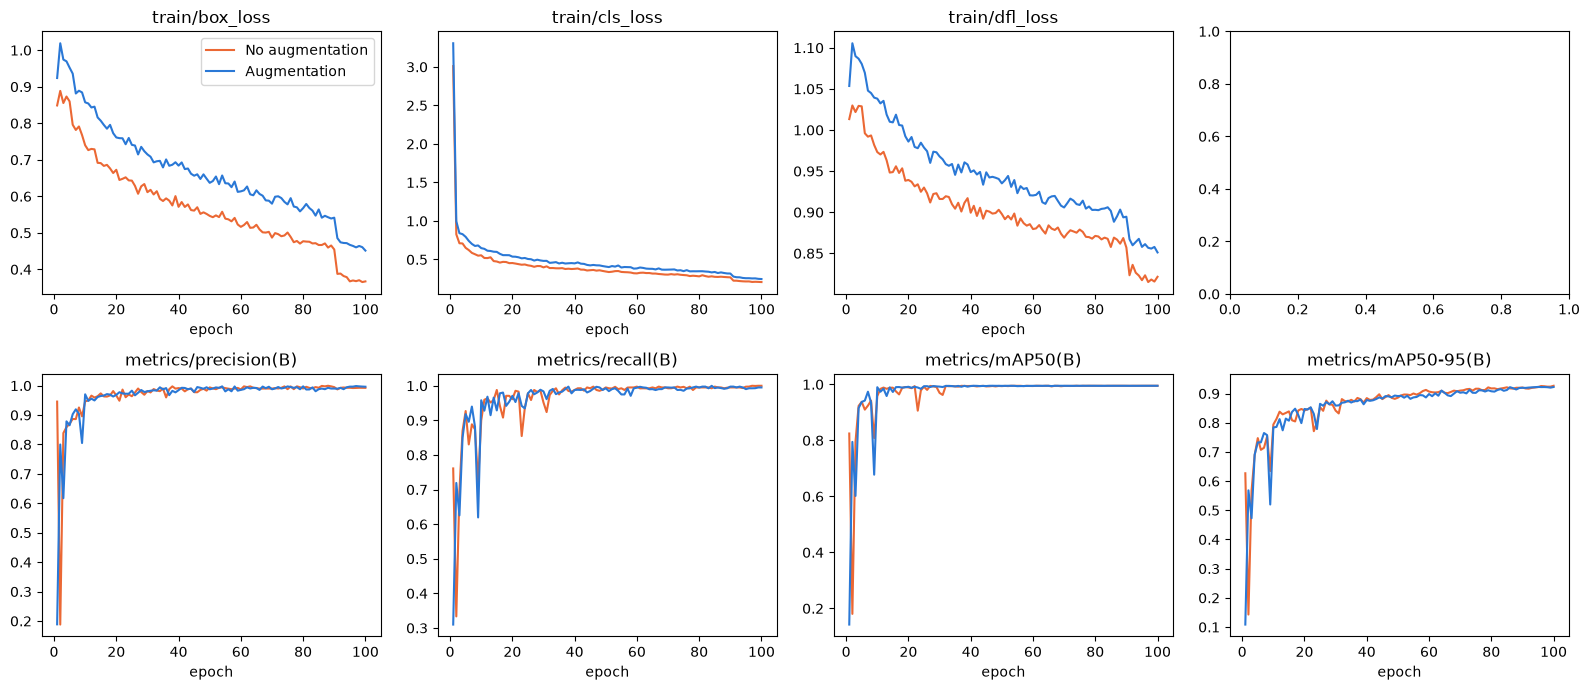

No augmentation    496.8
Augmentation       444.2
Name: minutes of training (CPU), dtype: float64

In [4]:
results = {label: pd.read_csv(OUTPUT_DIR / cfg["name"] / "results.csv").rename(columns=str.strip)
           for label, cfg in RUNS.items()}

loss_cols = ["train/box_loss", "train/cls_loss", "train/dfl_loss"]
metric_cols = ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]

fig, axes = plt.subplots(2, max(len(loss_cols), len(metric_cols)), figsize=(16, 7))
for label, df in results.items():
    color = MODEL_COLORS[label]
    for ax, col in zip(axes[0], loss_cols):
        ax.plot(df.epoch, df[col], color=color, label=label)
        ax.set(title=col, xlabel="epoch")
    for ax, col in zip(axes[1], metric_cols):
        ax.plot(df.epoch, df[col], color=color, label=label)
        ax.set(title=col, xlabel="epoch")
axes[0, 0].legend()
plt.tight_layout()
plt.show()


def total_seconds(df):
    """Training time from the `time` column. If a run was resumed (yolo_1class_aug was cut by the
    Slurm time limit at epoch 72 and resumed), the column restarts from ~0, so the epochs are added up
    one by one instead of reading the last row."""
    seconds = df["time"].diff()
    seconds.iloc[0] = df["time"].iloc[0]
    restarted = seconds < 0
    seconds[restarted] = df["time"][restarted]
    return seconds.sum()


time_minutes = {label: total_seconds(df) / 60 for label, df in results.items()}
pd.Series(time_minutes, name="minutes of training (CPU)").round(1)

**Curvas de entrenamiento del detector de 1 clase (naranja: sin aumentos; azul: con aumentos).** Las tres pérdidas de entrenamiento bajan de forma continua; la corrida con aumentos queda por encima (`box_loss` final de 0,45 frente a 0,37) porque sus imágenes son más difíciles, lo cual no implica peor desempeño. En la época 91 se ve un escalón en la pérdida de ambas corridas, que coincide con las últimas 10 épocas, en las que Ultralytics apaga el mosaico por defecto. En validación, precisión, recall y mAP50 llegan a ~1,0 desde la época ~15–20 (mAP50 de 0,995 en las dos): con una sola clase y un IoU de 0,5 detectar el huevo es fácil, así que mAP50 está saturado y no discrimina. La métrica informativa es mAP50-95, que llega a 0,9224 con aumentos y 0,9267 sin ellos en la época 100 (promedio de las últimas 10 épocas: 0,9215 y 0,9221), una diferencia que no permite declarar una mejor. No hay señales de sobreajuste en las métricas de validación. Como `valid` es de la misma fuente que `train`, estas curvas no miden el efecto de los aumentos sobre fotos de otra fuente; eso se evalúa en las fotos externas.


## 3. Arquitectura

YOLO11n tiene una sola red para las dos corridas (sin/con aumentos): lo único que cambia entre ellas es
la receta de entrenamiento, no la arquitectura. Se describe una sola vez.

**Las tres partes.**

- **Backbone (columna vertebral).** Convoluciones que reducen la imagen (640×640 → mapas más chicos, más
  canales) y extraen rasgos: bordes, texturas, formas. Usa bloques **C3k2** (una versión más liviana de
  los bloques C2f de YOLOv8: divide los canales, pasa una parte por convoluciones pequeñas y la junta con
  la otra) y, antes del final, un bloque **C2PSA** (atención a una parte de los canales, nuevo en YOLO11)
  que ayuda a la red a enfocarse en la zona del huevo y no en el fondo del campo del microscopio. Al final
  del backbone hay un **SPPF** (Spatial Pyramid Pooling - Fast): aplica max-pooling a varias escalas y las
  junta, para que la red vea el huevo entero sin importar su tamaño en la foto.
- **Neck (cuello).** Combina los mapas de distintas resoluciones del backbone (tipo PAN/FPN): sube la
  información de los mapas chicos (más contexto, menos detalle) y la mezcla con los mapas grandes (más
  detalle, menos contexto). Así la misma red detecta huevos chicos y grandes en la foto.
- **Head (cabeza), anchor-free.** Por cada celda del mapa final predice: (1) la caja, como una
  distribución de distancias a los 4 bordes en vez de un número fijo (**DFL**, Distribution Focal Loss) y
  (2) la clase (1 clase), con una probabilidad por clase. No usa cajas ancla
  predefinidas (a diferencia de YOLOv3-v5): cada celda decide directamente dónde está el borde.
- **Pérdida.** Caja: **CIoU** (penaliza no solo el solapamiento sino la distancia entre centros y la
  forma) + DFL. Clase: entropía cruzada binaria (BCE) por clase.

In [5]:
model_for_info = YOLO(str(MODELS["No augmentation"]))
layer_summary = model_for_info.info(detailed=True)
layer_summary

layer                                    name                type  gradient  parameters               shape        mu     sigma


    0                     model.0.conv.weight              Conv2d     False         432       [16, 3, 3, 3] -0.000906     0.152        float32


    1                       model.0.bn.weight         BatchNorm2d     False          16                [16]      2.98      1.92        float32


    1                         model.0.bn.bias         BatchNorm2d     False          16                [16]     0.709      4.35        float32


    2                             model.0.act                SiLU     False           0                  []         -         -              -


    3                     model.1.conv.weight              Conv2d     False        4608      [32, 16, 3, 3]    0.0022    0.0823        float32


... (263 outputs left out)

  181                model.23.dfl.conv.weight              Conv2d     False          16       [1, 16, 1, 1]       7.5      4.76        float32


YOLO11n summary: 182 layers, 2,604,883 parameters, 0 gradients, 6.6 GFLOPs


/home/scar-test/.conda/envs/geohelmintos/lib/python3.12/site-packages/ultralytics/utils/torch_utils.py:575: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1861.)
  f"{i:>5g}{f'{mn}.{pn}':>40}{mt:>20}{p.requires_grad!r:>10}{p.numel():>12g}{list(p.shape)!s:>20}{p.mean():>10.3g}{p.std():>10.3g}{str(p.dtype).replace('torch.', ''):>15}"


(182, 2604883, 0, 6.5671424)

**Diagrama de bloques.** Versión simplificada de lo descrito arriba, con el tamaño del mapa en cada
etapa (para una entrada de 640×640).

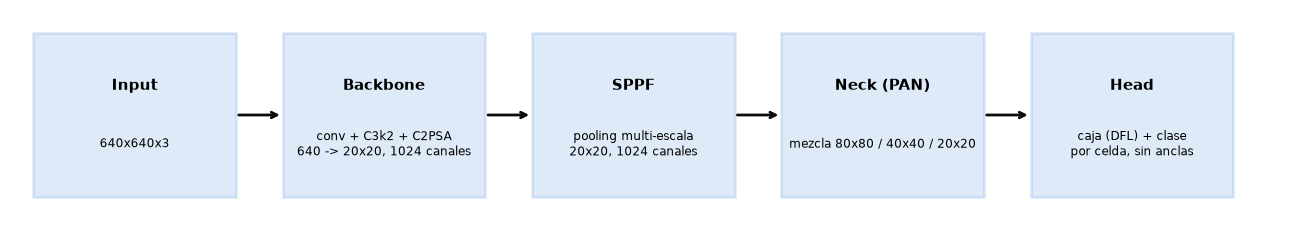

In [6]:
def draw_pipeline(ax, boxes):
    """boxes: list of (label, detail) drawn left to right with arrows between them."""
    width, gap = 2.6, 0.6
    for i, (label, detail) in enumerate(boxes):
        x = i * (width + gap)
        ax.add_patch(Rectangle((x, 0), width, 1.4, facecolor="#2a78d6", alpha=0.15, edgecolor="#2a78d6", linewidth=2))
        ax.text(x + width / 2, 0.95, label, ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(x + width / 2, 0.45, detail, ha="center", va="center", fontsize=8.5)
        if i > 0:
            ax.annotate("", xy=(x, 0.7), xytext=(x - gap, 0.7),
                        arrowprops=dict(arrowstyle="->", linewidth=2, color="#0b0b0b"))
    ax.set_xlim(-0.3, len(boxes) * (width + gap))
    ax.set_ylim(-0.2, 1.6)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(13, 2.4))
draw_pipeline(ax, [
    ("Input", "640x640x3"),
    ("Backbone", "conv + C3k2 + C2PSA\n640 -> 20x20, 1024 canales"),
    ("SPPF", "pooling multi-escala\n20x20, 1024 canales"),
    ("Neck (PAN)", "mezcla 80x80 / 40x40 / 20x20"),
    ("Head", "caja (DFL) + clase\npor celda, sin anclas"),
])
plt.tight_layout()
plt.show()

## 4. Métricas en `valid`

`model.val()` corre sobre el split de validación y da las métricas estándar de detección.
Ultralytics guarda además, dentro de la carpeta de cada corrida, las curvas de precisión/recall/F1 contra
el umbral de confianza y la matriz de confusión se muestran tal cual las genera la librería, sin
recalcularlas a mano.

In [7]:
val_metrics = {}
for label, weights in MODELS.items():
    metrics = YOLO(str(weights)).val(data=str(RUNS[label]["data"]), split="val", device=DEVICE, plots=True,
                                      project=str(OUTPUT_DIR), name=RUNS[label]["name"], exist_ok=True)
    val_metrics[label] = {
        "mAP50": metrics.box.map50, "mAP50-95": metrics.box.map,
        "precision": metrics.box.mp, "recall": metrics.box.mr,
    }
val_table = pd.DataFrame(val_metrics).T
val_table["F1"] = 2 * val_table.precision * val_table.recall / (val_table.precision + val_table.recall)
val_table.round(3)

Ultralytics 8.4.195 🚀 Python-3.12.16 torch-2.13.0+cu129 CUDA:0 (NVIDIA H100 NVL, 95320MiB)


YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 299.6±133.8 MB/s, size: 47.7 KB)



val: Scanning /home/scar-test/deep-learning/data/raw/valid/labels... 311 images, 0 backgrounds, 0 corrupt: 75% ━━━━━━━━━─── 311/410 924.5it/s 0.1s<0.1s


val: Scanning /home/scar-test/deep-learning/data/raw/valid/labels... 410 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 410/410 3.1Kit/s 0.1s

val: New cache created: /home/scar-test/deep-learning/data/raw/valid/labels.cache


... (29 outputs left out)

                   all        410        413      0.998      0.992      0.995      0.923


Speed: 0.5ms preprocess, 0.9ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/scar-test/deep-learning/dl/outputs/yolo/yolo_1class_aug


,mAP50,mAP50-95,precision,recall,F1
No augmentation,0.995,0.928,0.993,1.000,0.996
Augmentation,0.995,0.923,0.998,0.992,0.995


**Evaluación final del detector de 1 clase en `valid` (413 huevos).** Con y sin aumentos, el detector queda prácticamente empatado: mAP50 de 0,995 en ambos, F1 de 0,996 (sin aumentos) y 0,995 (con aumentos). El mAP50 está saturado, porque con una sola clase y un IoU de 0,5 detectar el huevo es fácil, así que no sirve para decidir. Hay un pequeño intercambio entre precisión y recall: sin aumentos encuentra todos los huevos (recall 1,000) con alguna caja de más (precisión 0,993); con aumentos casi no genera cajas falsas (precisión 0,998) pero pierde unos pocos huevos (recall 0,992). El mAP50-95 es 0,005 menor con aumentos (0,923 frente a 0,928), una diferencia dentro del ruido (el promedio de las últimas 10 épocas fue de 0,9215 y 0,9221). La precisión y el recall corresponden al umbral de confianza que maximiza el F1, y no al 0,25 de las fotos externas. Como `valid` es de la misma fuente que `train`, esta tabla no permite decidir si los aumentos valen la pena; eso se evalúa en las fotos externas.


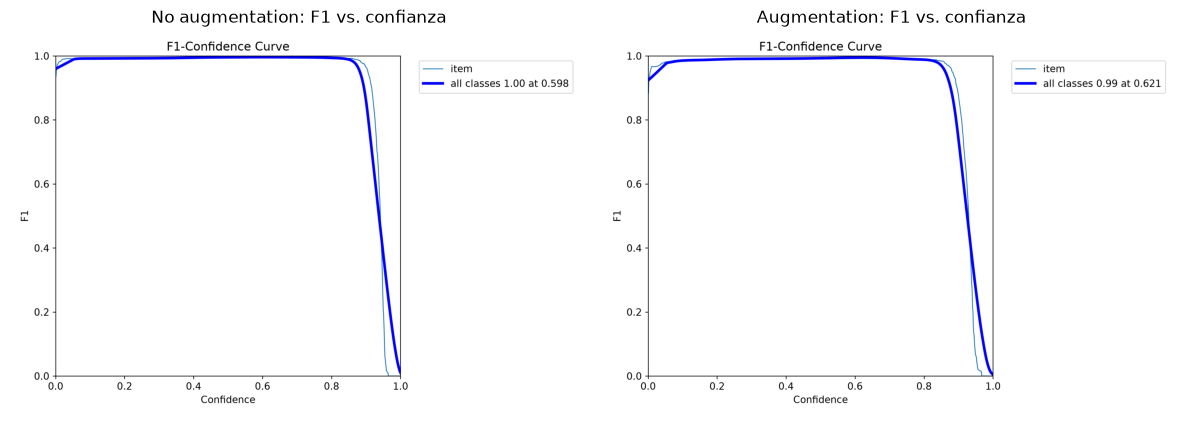

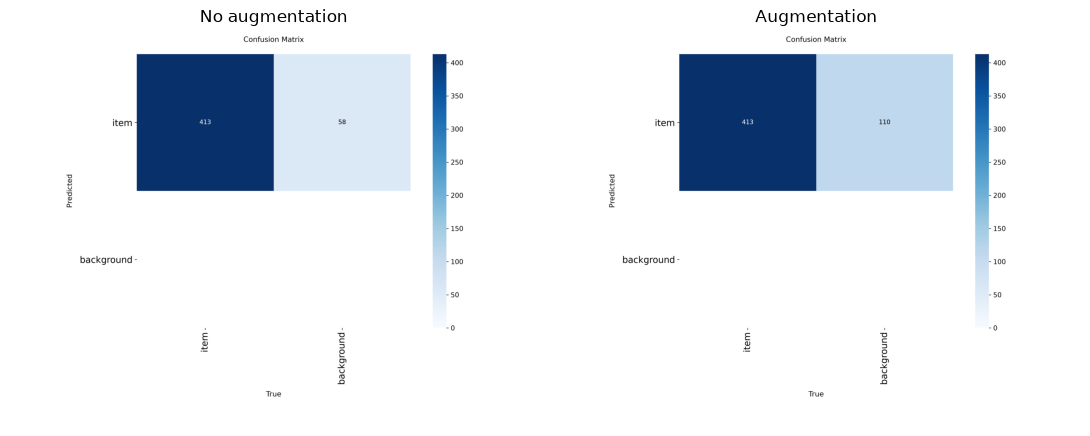

In [8]:
def find_plot(run_dir, *names):
    """Ultralytics names the curves F1_curve.png or BoxF1_curve.png depending on its version."""
    for name in names:
        if (run_dir / name).is_file():
            return run_dir / name
    raise FileNotFoundError(f"none of {names} in {run_dir}")


fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 5))
for ax, (label, cfg) in zip(axes, RUNS.items()):
    curve_path = find_plot(OUTPUT_DIR / cfg["name"], "BoxF1_curve.png", "F1_curve.png")
    ax.imshow(Image.open(curve_path))
    ax.set_title(f"{label}: F1 vs. confianza")
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 5))
for ax, (label, cfg) in zip(axes, RUNS.items()):
    confusion_path = find_plot(OUTPUT_DIR / cfg["name"], "confusion_matrix.png")
    ax.imshow(Image.open(confusion_path))
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Matrices de confusión del detector de 1 clase (`valid`, 413 huevos; filas = predicho, columnas = real).** Con y sin aumentos se detectan los 413 huevos y no se pierde ninguno. La diferencia está en las cajas sin huevo: 58 sin aumentos y 110 con aumentos. Estas cifras son altas porque la matriz se calcula con un umbral de confianza de 0,001 (el valor por defecto de la validación de Ultralytics, que aquí aplica porque `conf` no se fijó), de modo que cuenta cajas de confianza casi nula; a partir de esos conteos, la precisión en ese umbral sería de ~0,88 sin aumentos y ~0,79 con aumentos, frente a 0,993 y 0,998 en el umbral que maximiza el F1. La mayor cantidad de falsas alarmas con aumentos coincide con el F1 más bajo de su curva a confianza cercana a 0. Con un umbral operativo de 0,25 estas cajas casi desaparecen, por lo que la matriz no permite elegir entre las dos corridas; muestra que, con la máxima sensibilidad, el detector encuentra todos los huevos de `valid`.


## 5. Fotos externas

Igual que en `detector/notebooks/compare_detectors.ipynb`: cada modelo se corre una vez sobre cada foto
externa, guardando todas las cajas con su puntaje; el umbral se aplica después, sin reinferir.

In [9]:
external_photos = pd.read_csv(EXTERNAL_CSV)
photos_on_disk = {p.name for p in EXTERNAL_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES}
assert photos_on_disk == set(external_photos.image), "fix external.csv first"
external_photos["n_items"] = external_photos.n_items.astype(int)
test_photos = external_photos[external_photos.uso == "prueba"]
print(f"{len(test_photos)} test photos with {test_photos.n_items.sum()} eggs")

98 test photos with 101 eggs


In [10]:
def detect_all(weights_path, image_paths):
    model = YOLO(str(weights_path))
    results = model.predict(source=[str(p) for p in image_paths], imgsz=IMAGE_SIZE, conf=CONF_LOWEST,
                             max_det=MAX_BOXES_PER_PHOTO, device=DEVICE, stream=True, verbose=False)
    rows = []
    for result in results:
        for (x1, y1, x2, y2), score, cls in zip(result.boxes.xyxy.tolist(), result.boxes.conf.tolist(),
                                                 result.boxes.cls.tolist()):
            rows.append({"image": Path(result.path).name, "score": score, "species": result.names[int(cls)],
                         "x1": x1, "y1": y1, "x2": x2, "y2": y2})
    return pd.DataFrame(rows, columns=["image", "score", "species", "x1", "y1", "x2", "y2"])


external_paths = [EXTERNAL_DIR / name for name in external_photos.image]
external_boxes = pd.concat(
    [detect_all(weights, external_paths).assign(model=label) for label, weights in MODELS.items()],
    ignore_index=True,
)
external_boxes.groupby("model").size().rename("boxes found (any score)")

model
Augmentation       181
No augmentation    118
Name: boxes found (any score), dtype: int64

In [11]:
def count_boxes(boxes, conf):
    every_pair = pd.MultiIndex.from_product([list(MODELS), test_photos.image], names=["model", "image"])
    kept = boxes[boxes.score >= conf]
    return kept.groupby(["model", "image"]).size().reindex(every_pair, fill_value=0)


def egg_counts(boxes, conf):
    real_eggs = test_photos.set_index("image").n_items
    box_counts = count_boxes(boxes, conf).unstack("model")
    counts = {}
    for label in MODELS:
        n_boxes = box_counts[label]
        found = np.minimum(n_boxes, real_eggs)
        counts[label] = {"real_eggs": int(real_eggs.sum()), "found": int(found.sum()),
                         "missed": int((real_eggs - found).sum()), "false_alarms": int((n_boxes - found).sum())}
    return pd.DataFrame.from_dict(counts, orient="index").rename_axis("model")


external_counts = egg_counts(external_boxes, CONF_THRESHOLD)
external_counts

,real_eggs,found,missed,false_alarms
model,,,,
No augmentation,101,88,13,3
Augmentation,101,100,1,7


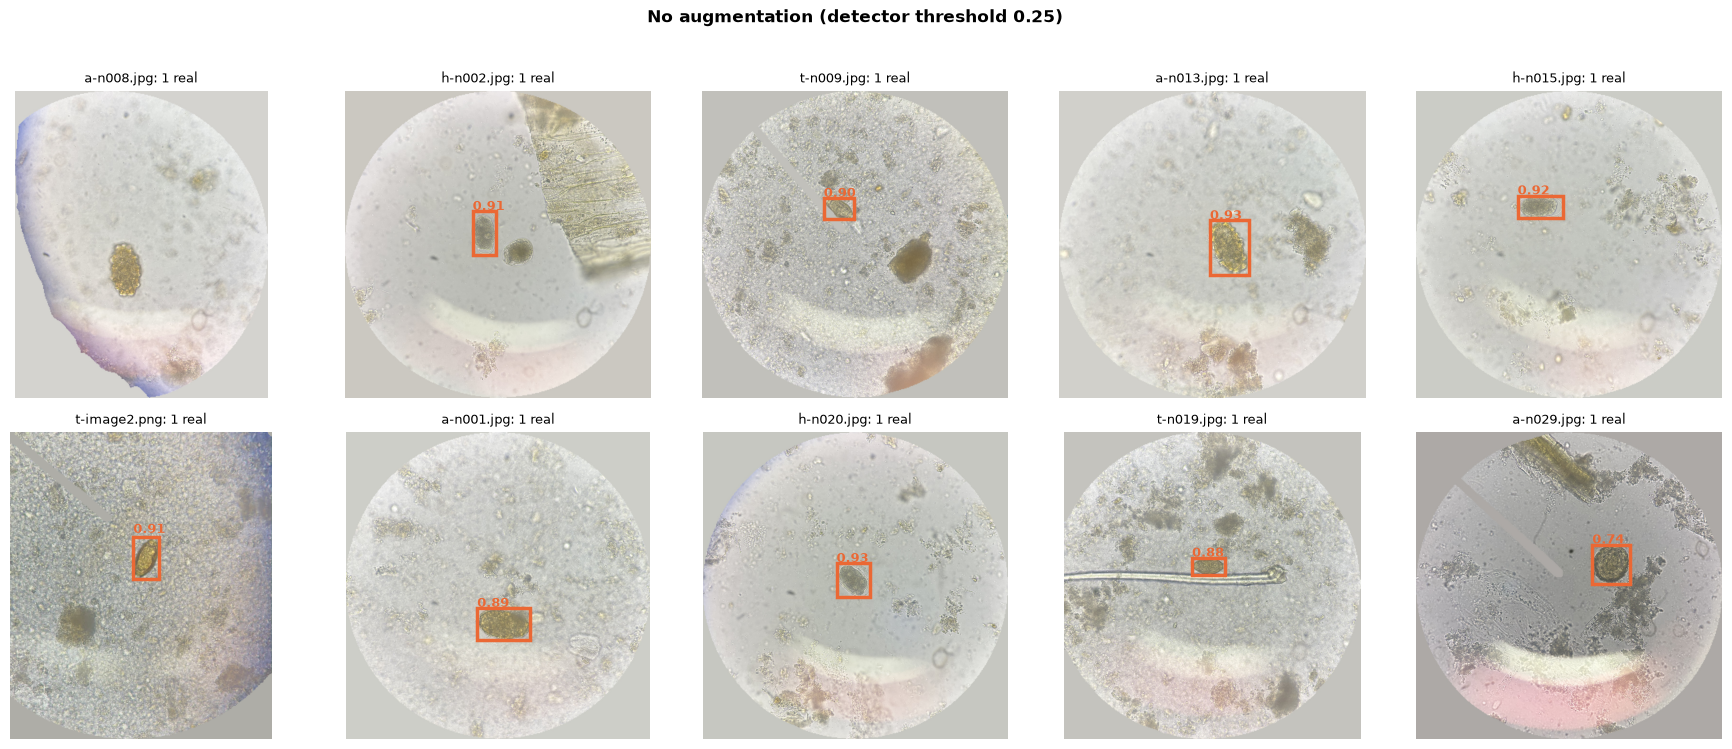

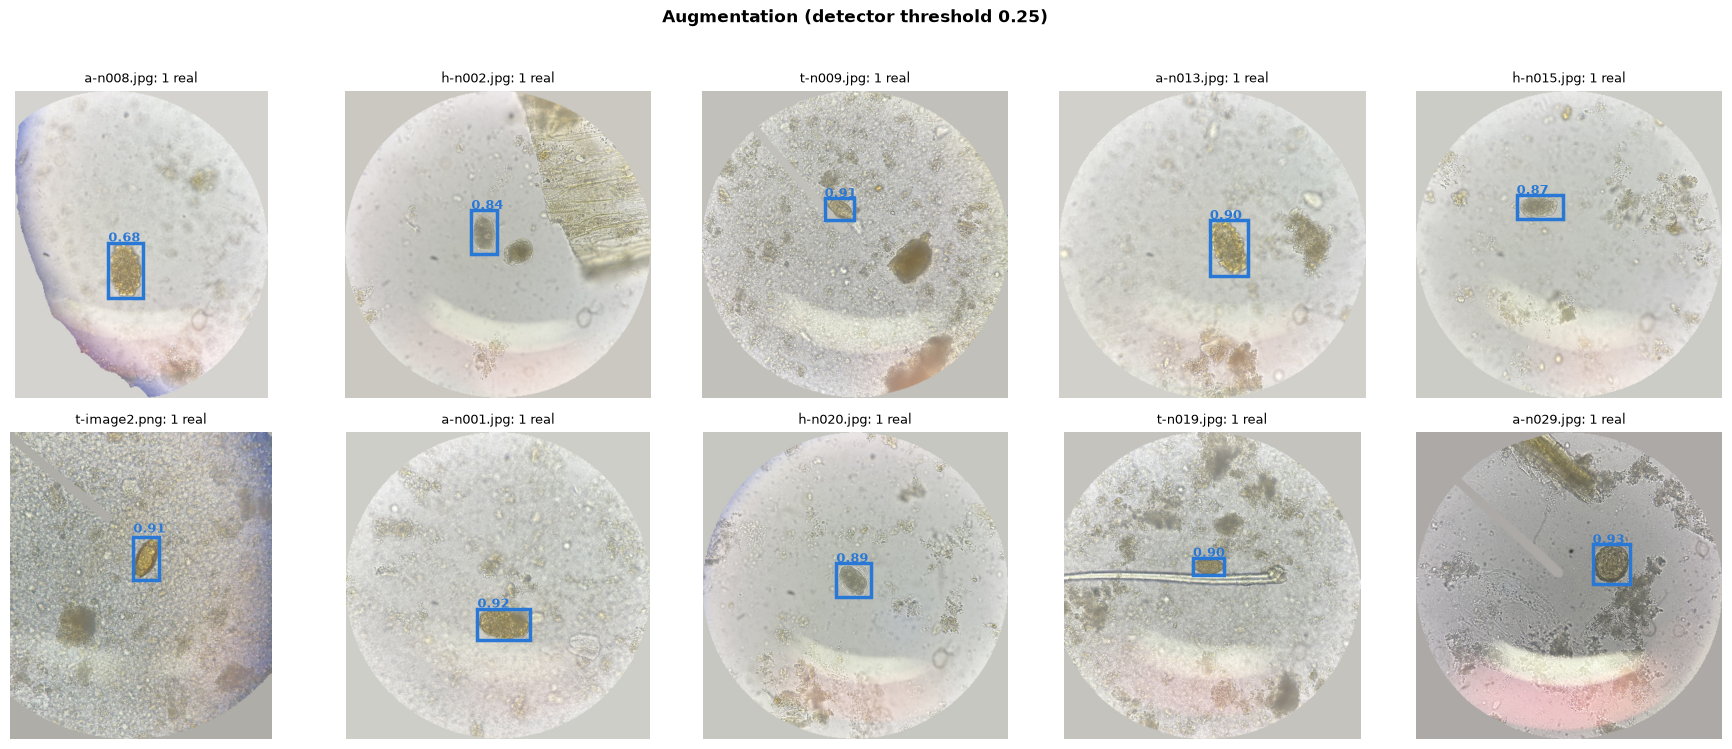

In [12]:
def draw_detections(ax, image_name, model_boxes, color):
    ax.imshow(ImageOps.exif_transpose(Image.open(EXTERNAL_DIR / image_name)))  # upright: iPhone JPGs carry EXIF rotation, and YOLO boxes are in the rotated frame
    shown = model_boxes[(model_boxes.image == image_name) & (model_boxes.score >= CONF_THRESHOLD)]
    for box in shown.itertuples():
        ax.add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                               fill=False, edgecolor=color, linewidth=2.5))
        label = f"{box.score:.2f}" if SINGLE_CLS else f"{box.species}: {box.score:.2f}"
        ax.text(box.x1, box.y1 - 10, label, color=color, fontsize=9, fontweight="bold")
    ax.axis("off")

N_SHOW, N_COLS = 10, 5
rng = np.random.default_rng(SEED)
pool = test_photos.copy()
pool["group"] = pool.species.fillna("control") if "species" in pool.columns else "all"
groups = {g: list(rng.permutation(df.image.values)) for g, df in pool.groupby("group")}
chosen = []
while len(chosen) < N_SHOW and any(groups.values()):
    for g in groups:
        if groups[g] and len(chosen) < N_SHOW:
            chosen.append(groups[g].pop())
sample = external_photos.set_index("image").loc[chosen].reset_index()

n_rows = int(np.ceil(len(sample) / N_COLS))
for label in MODELS:
    model_boxes = external_boxes[external_boxes.model == label]
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.6 * N_COLS, 3.8 * n_rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, photo in zip(axes.ravel(), sample.itertuples()):
        draw_detections(ax, photo.image, model_boxes, MODEL_COLORS[label])
        ax.set_title(f"{photo.image}: {photo.n_items} real", fontsize=9)
    fig.suptitle(f"{label} (detector threshold {CONF_THRESHOLD})", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


**Detecciones en 10 fotos externas (5 por fila; arriba sin aumentos, abajo con aumentos; umbral 0,25).** Las cajas son ajustadas y con confianza alta (0,79 a 0,93 sin aumentos) y caen sobre objetos con forma de huevo. En las fotos visibles, la corrida con aumentos detecta un huevo que la otra no encuentra (a-n008, confianza 0,68) pero da confianzas más bajas en las demás (por ejemplo 0,84 frente a 0,91 en h-n002); son pocas fotos para generalizar, y la comparación está en la tabla de totales. En algunas fotos (h-n002, t-n009, t-image2) hay otro objeto ovalado oscuro sin caja y la caja está sobre uno más pequeño, y como el conteo compara cantidades y no ubicaciones, esas cajas contarían como aciertos aunque estén sobre el objeto equivocado; conviene que un parasitólogo las revise. Las fotos comparten artefactos del montaje (una media luna blanca inferior y bordes con tinte de color) que no se eliminan al recortar el campo.
